# Задача 1. Реакция пользователя

Классифицируем итоговую реакцию по диалогу: `negative`, `neutral` или `positive`.
Сравниваем три модели: MultinomialNB, LogisticRegression и LinearSVC. Сначала подбираем параметры на обучающей части, затем проверяем модели на отложенном тесте.

## Данные и тексты

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.base import clone
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             balanced_accuracy_score, ConfusionMatrixDisplay)
from sklearn.pipeline import Pipeline


In [3]:
df = pd.read_json("data/hw1_train.jsonl", lines=True)

df["reaction"] = df["labels"].apply(lambda x: x.get("reaction") if isinstance(x, dict) else None)
df_reaction = df[df["reaction"].notna()].copy()

print("Размер датасета:", df_reaction.shape)

Размер датасета: (3000, 6)


In [4]:
def clean_text(text):
    # удаляем иероглифы
    text = re.sub(r"[\u3400-\u9fff]+", " ", text)
    # убираем лишние пробелы и табуляции
    text = re.sub(r"[ \t]+", " ", text)
    # куски кода в markdown 
    text = re.sub(r"```.*?```", " ", text, flags=re.DOTALL)
    # Убираем лишние пустые строки
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()


def get_dialog_text(turns):
    text = "\n".join(
        turn["role"] + ": " + turn["text"]
        for turn in turns
    )
    return clean_text(text)


df_reaction["dialog_text"] = df_reaction["turns"].apply(get_dialog_text)

X = df_reaction["dialog_text"]
y = df_reaction["reaction"]

print("Количество текстов:", len(X))
print("Количество меток:", len(y))
print("\nПример текста:")
print(X.iloc[0][:1000])
print("\nМетка реакции:", y.iloc[0])


Количество текстов: 3000
Количество меток: 3000

Пример текста:
user: it’s like: 1+1=2, but 1+1=2+1+1=? is undefined. <–can you tell which modulus we can possibly use in this concept and into which it may result?
In the context of the equation “1+1=2+1+1=?,” if we want to explore the possibility of using a modulus to determine the result, we can consider different modulus values and see how they affect the equation.

Modulus, also known as the remainder when dividing a number by another, is often denoted by the symbol “%”. It can be used to find the remainder of a division operation.

Let’s consider a few examples:

1. Modulus 3:
Using modulus 3, we would evaluate remainders when dividing numbers by 3. Therefore:
1 + 1 = 2 % 3 + 1 % 3 + 1 % 3
= 2 + 1 + 1
= 4

2. Modulus 4:
Using modulus 4, we would evaluate remainders when dividing numbers by 4. Therefore:
1 + 1 = 2 % 4 + 1 % 4 + 1 % 4
= 2 + 1 + 1
= 4

3. Modulus 5:
Using modulus 5, we would evaluate remainders when dividing numbers by

## Разделение выборки

Сначала объединяем очень похожие пользовательские запросы в группы, чтобы такие диалоги не оказались одновременно в обучении и тесте. Сохраняем исходную схему группировки и `StratifiedGroupKFold`.

In [5]:
df_reaction = df_reaction.reset_index(drop=True)

df_reaction["group"] = np.arange(len(df_reaction))

print(df_reaction[["dialog_id", "reaction", "group"]].head(5))

     dialog_id  reaction  group
0  d094012177e  positive      0
1  d306fbe61fe   neutral      1
2  dd6905952c7   neutral      2
3  d767a675896  negative      3
4  d7a6280ce8e  negative      4


In [6]:
# собираем только сообщения пользователей
df_reaction["user_text"] = df_reaction["turns"].apply(
    lambda turns: "\n".join(
        turn["text"]
        for turn in turns
        if turn["role"] == "user"
    )
)

# превращаем тексты в TF-IDF-векторы
vectorizer_groups = TfidfVectorizer(max_features=10000, stop_words="english")

X_groups = vectorizer_groups.fit_transform(
    df_reaction["user_text"]
)

knn = NearestNeighbors(n_neighbors=2, metric="cosine", algorithm="brute", n_jobs=-1)
knn.fit(X_groups)

distances, indices = knn.kneighbors(X_groups)

similarities = 1 - distances[:, 1]

print("Диалогов со сходством >= 0.95:", (similarities >= 0.95).sum())

Диалогов со сходством >= 0.95: 23


In [7]:
parent = list(range(len(df_reaction)))

def find(x):
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[root_b] = root_a

for i in range(len(df_reaction)):
    j = indices[i, 1]

    if i != j and similarities[i] >= 0.95:
        union(i, j)

df_reaction["group"] = [find(i) for i in range(len(df_reaction))]

print("Количество групп:", df_reaction["group"].nunique())
print("Групп с несколькими диалогами:", (df_reaction["group"].value_counts() > 1).sum())

Количество групп: 2987
Групп с несколькими диалогами: 10


Разобьем на train и test

In [8]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

train_idx, test_idx = next(sgkf.split(df_reaction["dialog_text"], df_reaction["reaction"], groups=df_reaction["group"]))

X_train = df_reaction.iloc[train_idx]["dialog_text"]
X_test = df_reaction.iloc[test_idx]["dialog_text"]

y_train = df_reaction.iloc[train_idx]["reaction"]
y_test = df_reaction.iloc[test_idx]["reaction"]

print("Размер train:", len(X_train))
print("Размер test:", len(X_test))

print("\nРаспределение классов в train:")
print(y_train.value_counts(normalize=True))

print("\nРаспределение классов в test:")
print(y_test.value_counts(normalize=True))

Размер train: 2403
Размер test: 597

Распределение классов в train:
reaction
neutral     0.585518
negative    0.311278
positive    0.103204
Name: proportion, dtype: float64

Распределение классов в test:
reaction
neutral     0.614740
negative    0.293132
positive    0.092127
Name: proportion, dtype: float64


In [9]:
train_groups = set(df_reaction.iloc[train_idx]["group"])
test_groups = set(df_reaction.iloc[test_idx]["group"])

common_groups = train_groups & test_groups
print("Количество общих групп:", len(common_groups))

Количество общих групп: 0


## Метрика и кросс-валидация

Основной показатель — **Macro-F1**: это среднее F1 по трём классам, поэтому редкий `positive` не теряется на фоне частого `neutral`. Дополнительно смотрим accuracy, precision, recall, balanced accuracy и матрицы ошибок.

Все подборы параметров проводим на **обучающей части** с пятью фолдами. Отложенный тест пока не используем.

$$
F1 = \frac{2 \cdot Precision \cdot Recall}{Precision + Recall}
$$


$$
Macro\text{-}F1 = \frac{F1_{positive} + F1_{neutral} + F1_{negative}}{3}
$$


## MultinomialNB

Сначала проверяем простой вариант, затем подбираем `alpha`, `fit_prior` и настройки TF-IDF. Для окончательного варианта **оставляем `alpha=0.1`**, как договорились; поиск с `alpha=0.07` сохраняем как историю экспериментов.

In [10]:
nb_pipeline = Pipeline([("tfidf", TfidfVectorizer(max_features=10000, ngram_range=(1, 1))), ("model", MultinomialNB())])

print(nb_pipeline)

Pipeline(steps=[('tfidf', TfidfVectorizer(max_features=10000)),
                ('model', MultinomialNB())])


In [11]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

train_groups = df_reaction.iloc[train_idx]["group"]
nb_scores = cross_val_score(nb_pipeline, X_train, y_train, groups=train_groups, cv=cv, scoring="f1_macro", n_jobs=-1)

print("Macro-F1 на каждой части кросс-валидации:", nb_scores)
print("Средний Macro-F1:", nb_scores.mean())
print("Стандартное отклонение:", nb_scores.std())

Macro-F1 на каждой части кросс-валидации: [0.41185694 0.42408996 0.40418199 0.41395349 0.41858679]
Средний Macro-F1: 0.41453383214986667
Стандартное отклонение: 0.006669471592885945


In [12]:
param_grid_nb = {
    "model__alpha": [0.1, 0.5, 1.0, 5.0],
    "model__fit_prior": [True, False]
}

grid_nb = GridSearchCV(
    estimator=nb_pipeline,
    param_grid=param_grid_nb,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

grid_nb.fit(X_train, y_train, groups=train_groups)

print("Лучшие параметры:", grid_nb.best_params_)
print("Лучший средний Macro-F1:", grid_nb.best_score_)

Лучшие параметры: {'model__alpha': 0.1, 'model__fit_prior': False}
Лучший средний Macro-F1: 0.5059043285873257


In [13]:
param_grid_nb_fine = {
    "model__alpha": [0.03, 0.05, 0.07, 0.1, 0.13, 0.17, 0.2, 0.3],
    "model__fit_prior": [False]
}

grid_nb_fine = GridSearchCV(
    estimator=nb_pipeline,
    param_grid=param_grid_nb_fine,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

grid_nb_fine.fit(X_train, y_train, groups=train_groups)

print("Лучшие параметры:", grid_nb_fine.best_params_)
print("Лучший средний Macro-F1:", grid_nb_fine.best_score_)

Лучшие параметры: {'model__alpha': 0.03, 'model__fit_prior': False}
Лучший средний Macro-F1: 0.5103506425041472


In [14]:
results_nb = pd.DataFrame(grid_nb_fine.cv_results_)

display(
    results_nb[
        ["param_model__alpha", "mean_test_score", "std_test_score"]
    ].sort_values("param_model__alpha")
)

,param_model__alpha,mean_test_score,std_test_score
0,0.03,0.510351,0.031389
1,0.05,0.508276,0.031945
2,0.07,0.509872,0.030916
3,0.10,0.505904,0.024834
4,0.13,0.483787,0.028651
5,0.17,0.471537,0.024273
6,0.20,0.455891,0.019993
7,0.30,0.449593,0.019613


In [15]:
param_grid_nb_tfidf = {
    "model__alpha": [0.1],
    "model__fit_prior": [False],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__sublinear_tf": [False, True]
}

grid_nb_tfidf = GridSearchCV(
    estimator=nb_pipeline,
    param_grid=param_grid_nb_tfidf,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

grid_nb_tfidf.fit(X_train, y_train, groups=train_groups)

print("Лучшие параметры:", grid_nb_tfidf.best_params_)
print("Лучший средний Macro-F1:", grid_nb_tfidf.best_score_)

Лучшие параметры: {'model__alpha': 0.1, 'model__fit_prior': False, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}
Лучший средний Macro-F1: 0.5448946355379138


In [16]:
results_tfidf = pd.DataFrame(grid_nb_tfidf.cv_results_)

display(
    results_tfidf[[
        "param_tfidf__ngram_range",
        "param_tfidf__sublinear_tf",
        "mean_test_score",
        "std_test_score"
    ]].sort_values("mean_test_score", ascending=False)
)

,param_tfidf__ngram_range,param_tfidf__sublinear_tf,mean_test_score,std_test_score
3,"(1, 2)",True,0.544895,0.045162
2,"(1, 2)",False,0.528793,0.031588
1,"(1, 1)",True,0.520181,0.027386
0,"(1, 1)",False,0.505904,0.024834


In [17]:
# лучшая конфигурация Naive Bayes
best_nb = grid_nb_tfidf.best_estimator_

# предсказания с помощью кросс-валидации
y_pred_nb = cross_val_predict(
    best_nb,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    n_jobs=-1
)

print("Accuracy:", accuracy_score(y_train, y_pred_nb))
print("Macro-F1:", f1_score(y_train, y_pred_nb, average="macro"))

print("\nClassification Report:")
print(classification_report(y_train, y_pred_nb, zero_division=0))

Accuracy: 0.6208905534748231
Macro-F1: 0.5464926596119435

Classification Report:
              precision    recall  f1-score   support

    negative       0.57      0.60      0.58       748
     neutral       0.76      0.66      0.71      1407
    positive       0.29      0.44      0.35       248

    accuracy                           0.62      2403
   macro avg       0.54      0.57      0.55      2403
weighted avg       0.65      0.62      0.63      2403



In [18]:
bal_acc = balanced_accuracy_score(y_train, y_pred_nb)

print("Balanced Accuracy:", bal_acc)

Balanced Accuracy: 0.5673880733922083


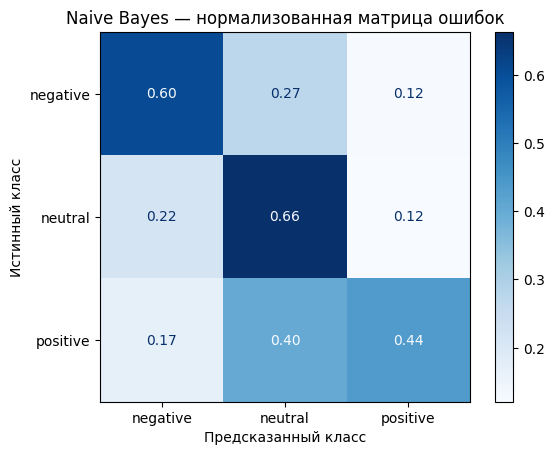

In [19]:
classes = ["negative", "neutral", "positive"]

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_nb,
    labels=classes,
    normalize="true",
    cmap="Blues",
    values_format=".2f"
)

plt.title("Naive Bayes — нормализованная матрица ошибок")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.show()

## LogisticRegression

Сравниваем обычную логистическую регрессию с вариантом `class_weight="balanced"`, затем подбираем `C` на тех же фолдах.

In [20]:
lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        min_df=2,
        max_df=0.95,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("model", LogisticRegression(
        C=1.0,
        class_weight=None,
        max_iter=1000,
        random_state=42
    ))
])

lr_scores = cross_val_score(
    lr_pipeline,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Macro-F1 на каждой части кросс-валидации:", lr_scores)
print("Средний Macro-F1:", lr_scores.mean())
print("Стандартное отклонение:", lr_scores.std())

Macro-F1 на каждой части кросс-валидации: [0.49616682 0.54882904 0.50883026 0.54047451 0.51424627]
Средний Macro-F1: 0.5217093795883576
Стандартное отклонение: 0.01980705811566529


In [21]:
lr_balanced_pipeline = clone(lr_pipeline)

lr_balanced_pipeline.set_params(
    model__class_weight="balanced"
)

lr_balanced_scores = cross_val_score(
    lr_balanced_pipeline,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Macro-F1 на каждой части:", lr_balanced_scores)
print("Средний Macro-F1:", lr_balanced_scores.mean())
print("Стандартное отклонение:", lr_balanced_scores.std())


Macro-F1 на каждой части: [0.62775016 0.62262539 0.61251053 0.5735206  0.55286095]
Средний Macro-F1: 0.5978535271492846
Стандартное отклонение: 0.02945744210230683


In [22]:
param_grid_lr = {
    "model__C": [0.1, 0.3, 1.0, 3.0, 10.0]
}

grid_lr = GridSearchCV(
    estimator=lr_balanced_pipeline,
    param_grid=param_grid_lr,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

grid_lr.fit(X_train, y_train, groups=train_groups)

print("Лучшие параметры:", grid_lr.best_params_)
print("Лучший средний Macro-F1:", grid_lr.best_score_)

results_lr = pd.DataFrame(grid_lr.cv_results_)

display(
    results_lr[
        ["param_model__C", "mean_test_score", "std_test_score"]
    ].sort_values("param_model__C")
)

Лучшие параметры: {'model__C': 3.0}
Лучший средний Macro-F1: 0.6093143558850496


,param_model__C,mean_test_score,std_test_score
0,0.1,0.567777,0.041933
1,0.3,0.582541,0.039097
2,1.0,0.597854,0.029457
3,3.0,0.609314,0.032195
4,10.0,0.604026,0.024836


In [23]:
best_lr = grid_lr.best_estimator_

y_pred_lr = cross_val_predict(
    best_lr,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    n_jobs=-1
)

print("Accuracy:", accuracy_score(y_train, y_pred_lr))
print("Balanced Accuracy:", balanced_accuracy_score(y_train, y_pred_lr))
print("Macro-F1:", f1_score(y_train, y_pred_lr, average="macro"))

print("\nClassification Report:")
print(classification_report(y_train, y_pred_lr, zero_division=0))

Accuracy: 0.6991260923845194
Balanced Accuracy: 0.5976155953109421
Macro-F1: 0.6106052950254133

Classification Report:
              precision    recall  f1-score   support

    negative       0.65      0.62      0.63       748
     neutral       0.75      0.80      0.77      1407
    positive       0.49      0.38      0.43       248

    accuracy                           0.70      2403
   macro avg       0.63      0.60      0.61      2403
weighted avg       0.69      0.70      0.69      2403



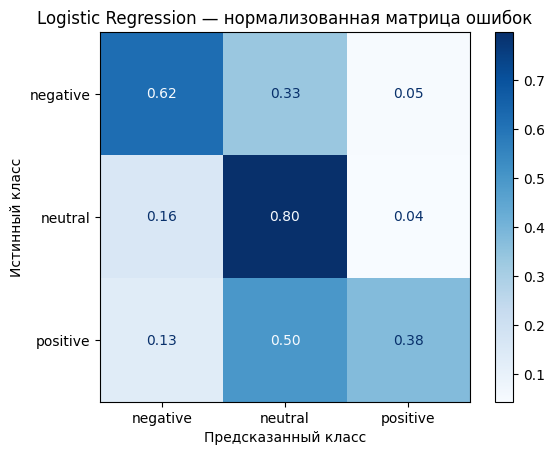

In [24]:
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_lr,
    labels=classes,
    normalize="true",
    cmap="Blues",
    values_format=".2f"
)

plt.title("Logistic Regression — нормализованная матрица ошибок")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.show()

## LinearSVC

Аналогично сравниваем модель без балансировки и с балансировкой, затем подбираем `C`.

In [25]:
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        min_df=2,
        max_df=0.95,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("model", LinearSVC(
        C=1.0,
        class_weight=None,
        max_iter=5000,
        random_state=42
    ))
])

svm_scores = cross_val_score(
    svm_pipeline,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Macro-F1 на каждой части кросс-валидации:", svm_scores)
print("Средний Macro-F1:", svm_scores.mean())
print("Стандартное отклонение:", svm_scores.std())

Macro-F1 на каждой части кросс-валидации: [0.60024796 0.59830191 0.60153186 0.56097069 0.56515189]
Средний Macro-F1: 0.5852408615183936
Стандартное отклонение: 0.01818685870351149


In [26]:
svm_balanced_pipeline = clone(svm_pipeline)

svm_balanced_pipeline.set_params(
    model__class_weight="balanced"
)

svm_balanced_scores = cross_val_score(
    svm_balanced_pipeline,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Macro-F1 на каждой части:", svm_balanced_scores)
print("Средний Macro-F1:", svm_balanced_scores.mean())
print("Стандартное отклонение:", svm_balanced_scores.std())

Macro-F1 на каждой части: [0.61322055 0.6081294  0.62509298 0.59464625 0.57277052]
Средний Macro-F1: 0.6027719400131273
Стандартное отклонение: 0.017900930054346693


In [27]:
param_grid_svm = {
    "model__C": [0.1, 0.3, 1.0, 3.0, 10.0]
}

grid_svm = GridSearchCV(
    estimator=svm_balanced_pipeline,
    param_grid=param_grid_svm,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

grid_svm.fit(X_train, y_train, groups=train_groups)

print("Лучшие параметры:", grid_svm.best_params_)
print("Лучший средний Macro-F1:", grid_svm.best_score_)

results_svm = pd.DataFrame(grid_svm.cv_results_)

display(
    results_svm[
        ["param_model__C", "mean_test_score", "std_test_score"]
    ].sort_values("param_model__C")
)

Лучшие параметры: {'model__C': 0.3}
Лучший средний Macro-F1: 0.6145460728037403


,param_model__C,mean_test_score,std_test_score
0,0.1,0.600023,0.035393
1,0.3,0.614546,0.030651
2,1.0,0.602772,0.017901
3,3.0,0.587260,0.014723
4,10.0,0.578056,0.015543


In [28]:
best_svm = grid_svm.best_estimator_

y_pred_svm = cross_val_predict(
    best_svm,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    n_jobs=-1
)

print("Accuracy:", accuracy_score(y_train, y_pred_svm))
print("Balanced Accuracy:", balanced_accuracy_score(y_train, y_pred_svm))
print("Macro-F1:", f1_score(y_train, y_pred_svm, average="macro"))

print("\nClassification Report:")
print(classification_report(y_train, y_pred_svm, zero_division=0))

Accuracy: 0.7191011235955056
Balanced Accuracy: 0.5891036890675794
Macro-F1: 0.616239603718609

Classification Report:
              precision    recall  f1-score   support

    negative       0.68      0.59      0.63       748
     neutral       0.74      0.86      0.80      1407
    positive       0.62      0.32      0.42       248

    accuracy                           0.72      2403
   macro avg       0.68      0.59      0.62      2403
weighted avg       0.71      0.72      0.71      2403



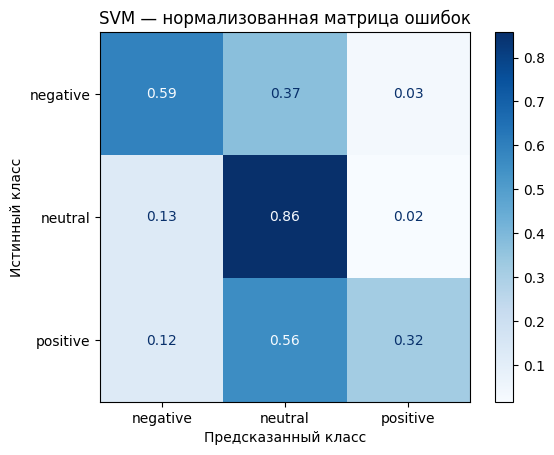

In [29]:
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_svm,
    labels=classes,
    normalize="true",
    cmap="Blues",
    values_format=".2f"
)

plt.title("SVM — нормализованная матрица ошибок")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.show()

## Сравнение по кросс-валидации

Здесь собраны предсказания, полученные на фолдах обучающей части. Так удобнее сравнить ошибки классов. **Замечание:** параметры мы уже выбирали по этим же фолдам, поэтому для окончательной оценки качества используем отдельный тест ниже.

In [30]:
from sklearn.metrics import precision_score, recall_score

cv_predictions = {
    "Naive Bayes": y_pred_nb,
    "Logistic Regression": y_pred_lr,
    "SVM": y_pred_svm
}

cv_results = []
for name, prediction in cv_predictions.items():
    cv_results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_train, prediction),
        "Macro-precision": precision_score(y_train, prediction, average="macro", zero_division=0),
        "Macro-recall": recall_score(y_train, prediction, average="macro", zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_train, prediction),
        "Macro-F1": f1_score(y_train, prediction, average="macro")
    })

display(pd.DataFrame(cv_results).round(4))

,Модель,Accuracy,Macro-precision,Macro-recall,Balanced accuracy,Macro-F1
0,Naive Bayes,0.6209,0.5376,0.5674,0.5674,0.5465
1,Logistic Regression,0.6991,0.6295,0.5976,0.5976,0.6106
2,SVM,0.7191,0.6800,0.5891,0.5891,0.6162


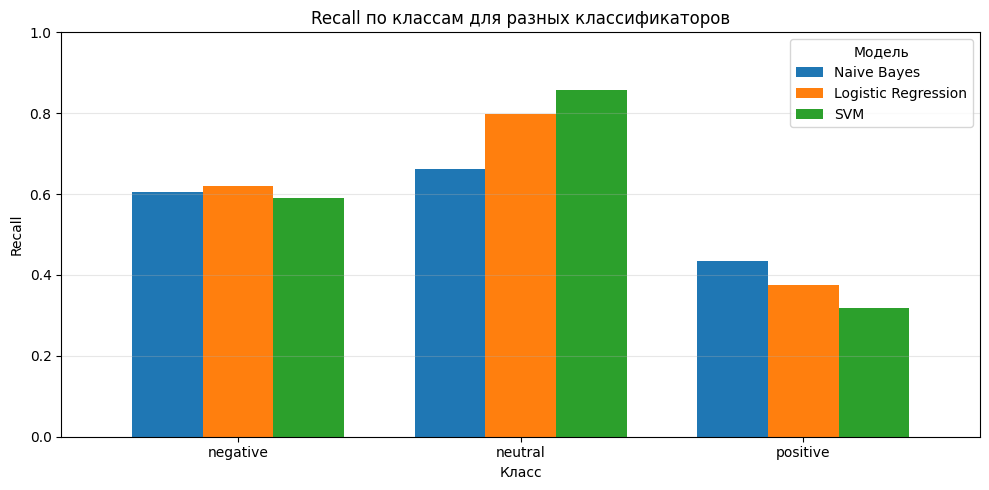

In [31]:
from sklearn.metrics import recall_score

recall_data = pd.DataFrame({
    "Naive Bayes": recall_score(y_train, y_pred_nb, labels=classes, average=None),
    "Logistic Regression": recall_score(y_train, y_pred_lr,labels=classes, average=None),
    "SVM": recall_score(y_train, y_pred_svm, labels=classes, average=None)
}, index=classes)

ax = recall_data.plot(kind="bar", figsize=(10, 5), rot=0, width=0.75)

plt.title("Recall по классам для разных классификаторов")
plt.xlabel("Класс")
plt.ylabel("Recall")
plt.ylim(0, 1)
plt.legend(title="Модель")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

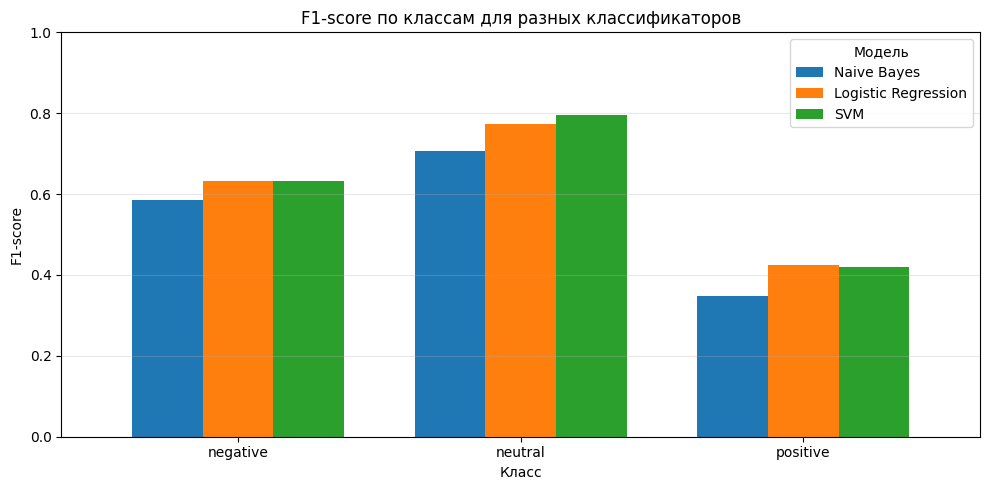

In [32]:
from sklearn.metrics import f1_score

f1_data = pd.DataFrame({
    "Naive Bayes": f1_score(
        y_train, y_pred_nb,
        labels=classes, average=None
    ),
    "Logistic Regression": f1_score(
        y_train, y_pred_lr,
        labels=classes, average=None
    ),
    "SVM": f1_score(
        y_train, y_pred_svm,
        labels=classes, average=None
    )
}, index=classes)

ax = f1_data.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
    width=0.75
)

plt.title("F1-score по классам для разных классификаторов")
plt.xlabel("Класс")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.legend(title="Модель")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Итоговое обучение и проверка на тесте

Используем **те же модели и параметры**, которые уже выбраны выше:

- MultinomialNB: `alpha=0.1`, `fit_prior=False`, TF-IDF с биграммами и `sublinear_tf=True`;
- LogisticRegression: `C=3.0`, `class_weight="balanced"`;
- LinearSVC: `C=0.3`, `class_weight="balanced"`.

Для каждой модели обучаем `Pipeline` на `X_train` и один раз проверяем на `X_test`. Настройки TF-IDF остаются внутри каждого `Pipeline` и подбираются только по обучающим текстам.

In [36]:
selected_models = {"Naive Bayes": best_nb, "Logistic Regression": best_lr, "SVM": best_svm}

final_models = {}
test_predictions = {}
test_results = []

for name, model in selected_models.items():
    final_model = clone(model)
    final_model.fit(X_train, y_train)
    prediction = final_model.predict(X_test)

    final_models[name] = final_model
    test_predictions[name] = prediction

    test_results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Macro-precision": precision_score(y_test, prediction, average="macro", zero_division=0),
        "Macro-recall": recall_score(y_test, prediction, average="macro", zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_test, prediction),
        "Macro-F1": f1_score(y_test, prediction, average="macro")
    })

test_table = pd.DataFrame(test_results)
display(test_table.round(4))

for name, prediction in test_predictions.items():
    print("\n", name)
    print(classification_report(y_test, prediction, zero_division=0))

,Модель,Accuracy,Macro-precision,Macro-recall,Balanced accuracy,Macro-F1
0,Naive Bayes,0.6080,0.5164,0.5550,0.5550,0.5261
1,Logistic Regression,0.7102,0.6349,0.6104,0.6104,0.6213
2,SVM,0.7337,0.6969,0.6314,0.6314,0.6571



 Naive Bayes
              precision    recall  f1-score   support

    negative       0.50      0.58      0.54       175
     neutral       0.78      0.65      0.71       367
    positive       0.27      0.44      0.33        55

    accuracy                           0.61       597
   macro avg       0.52      0.55      0.53       597
weighted avg       0.65      0.61      0.62       597


 Logistic Regression
              precision    recall  f1-score   support

    negative       0.62      0.58      0.60       175
     neutral       0.77      0.81      0.79       367
    positive       0.51      0.44      0.47        55

    accuracy                           0.71       597
   macro avg       0.63      0.61      0.62       597
weighted avg       0.70      0.71      0.71       597


 SVM
              precision    recall  f1-score   support

    negative       0.65      0.57      0.61       175
     neutral       0.77      0.85      0.81       367
    positive       0.67      0.47

In [37]:
for name, prediction in test_predictions.items():
    score = balanced_accuracy_score(y_test, prediction)
    print(f"Balanced accuracy for {name}: {score:.4f}")

Balanced accuracy for Naive Bayes: 0.5550
Balanced accuracy for Logistic Regression: 0.6104
Balanced accuracy for SVM: 0.6314


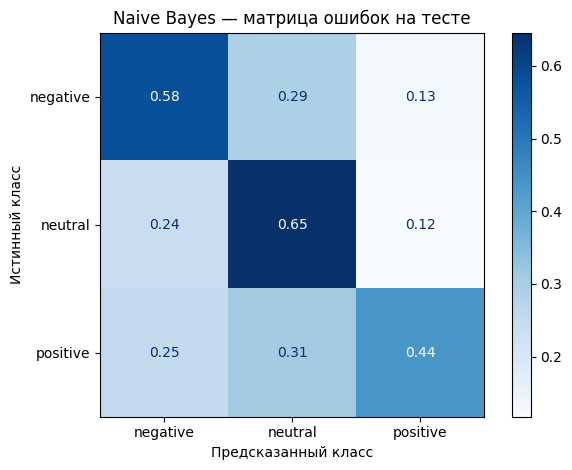

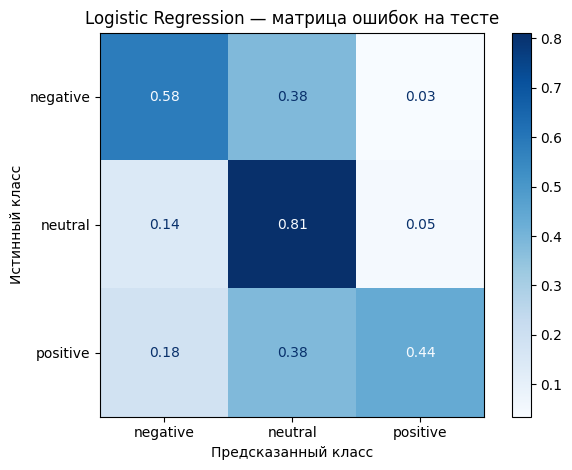

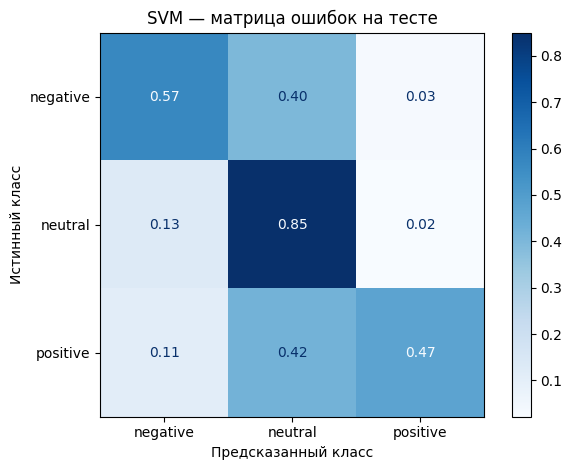

In [38]:
for name, prediction in test_predictions.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        prediction,
        labels=classes,
        normalize="true",
        cmap="Blues",
        values_format=".2f"
    )
    plt.title(name + " — матрица ошибок на тесте")
    plt.xlabel("Предсказанный класс")
    plt.ylabel("Истинный класс")
    plt.tight_layout()
    plt.show()

## Анализ ошибок

Посмотрим, какие реакции чаще всего путаются и на каких конкретных диалогах. По нескольким примерам удобно вручную проверить, почему модель могла ошибиться. Показаны только начала диалогов, чтобы не выводить огромные тексты.

In [39]:
for name, prediction in test_predictions.items():
    examples = df_reaction.iloc[test_idx][["dialog_id", "dialog_text", "reaction"]].copy()
    examples["prediction"] = prediction
    errors = examples[examples["reaction"] != examples["prediction"]].copy()

    print("\n", name, "— ошибок:", len(errors))
    print("Какие классы чаще всего путаются:")
    display(pd.crosstab(errors["reaction"], errors["prediction"]))

    errors["dialog_text"] = errors["dialog_text"].str.slice(0, 250)


 Naive Bayes — ошибок: 234
Какие классы чаще всего путаются:


prediction,negative,neutral,positive
reaction,,,
negative,0,51,22
neutral,87,0,43
positive,14,17,0



 Logistic Regression — ошибок: 173
Какие классы чаще всего путаются:


prediction,negative,neutral,positive
reaction,,,
negative,0,67,6
neutral,52,0,17
positive,10,21,0



 SVM — ошибок: 159
Какие классы чаще всего путаются:


prediction,negative,neutral,positive
reaction,,,
negative,0,70,5
neutral,47,0,8
positive,6,23,0


**Что видно по результатам:** на тесте модели часто путают `positive` с `neutral`. У SVM высокая полнота для `neutral`, но заметно более низкая для `positive`. Это объясняет, почему одной accuracy недостаточно: она не показывает, насколько плохо обнаруживается редкий класс.

## Сохранение моделей

In [72]:
from pathlib import Path
import joblib

Path("artifacts").mkdir(exist_ok=True)

for name, model in selected_models.items():
    model_all = clone(model)
    model_all.fit(X, y)
    filename = name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(model_all, Path("artifacts") / filename)